Create Librarys

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from google.colab import files

print("Upload week3_hypothetical_logistics_dataset.csv")
uploaded = files.upload()


Upload week3_hypothetical_logistics_dataset.csv


Saving week3_hypothetical_logistics_dataset.csv to week3_hypothetical_logistics_dataset.csv


In [2]:
df = pd.read_csv("week3_hypothetical_logistics_dataset.csv")
print("Dataset shape:", df.shape)
display(df.head())
print("\nData types:")
df.info()
print("\nMissing values:")
display(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (240, 10)


,shipment_id,order_date,region,transport_mode,distance_km,shipment_volume_units,delivery_time_days,promised_delivery_days,transport_cost_inr,on_time_delivery
0,SHP0001,2026-01-31,North,Rail,372.3,53,3.0,3.6,2729.52,1
1,SHP0002,2026-02-01,East,Air,413.1,123,1.9,1.5,6726.17,0
2,SHP0003,2026-01-16,South,Air,438.3,111,0.5,1.0,6924.52,1
3,SHP0004,2026-01-27,South,Road,367.4,206,2.5,2.6,4031.63,1
4,SHP0005,2026-05-22,South,Road,557.1,66,6.8,6.0,4500.80,0



Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   shipment_id             240 non-null    object 
 1   order_date              240 non-null    object 
 2   region                  240 non-null    object 
 3   transport_mode          240 non-null    object 
 4   distance_km             240 non-null    float64
 5   shipment_volume_units   240 non-null    int64  
 6   delivery_time_days      240 non-null    float64
 7   promised_delivery_days  240 non-null    float64
 8   transport_cost_inr      240 non-null    float64
 9   on_time_delivery        240 non-null    int64  
dtypes: float64(4), int64(2), object(4)
memory usage: 18.9+ KB

Missing values:


,0
shipment_id,0
order_date,0
region,0
transport_mode,0
distance_km,0
shipment_volume_units,0
delivery_time_days,0
promised_delivery_days,0
transport_cost_inr,0
on_time_delivery,0



Duplicate rows: 0


Problem Definition -->
delivery_time_days (regression). Features: distance, shipment volume, transportation cost, promised delivery days, transport mode, and region. Shipment IDs and the on-time outcome flag are not used as predictors.

In [3]:
target = "delivery_time_days"
features = ["distance_km", "shipment_volume_units", "transport_cost_inr",
            "promised_delivery_days", "transport_mode", "region"]
data = df[features + [target]].dropna(subset=[target]).copy()
X = data[features]
y = data[target]

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = [c for c in features if c not in numeric_features]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 192
Testing rows: 48


Preprocessing and model selection

In [4]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42, max_depth=4),
    "Random Forest": RandomForestRegressor(random_state=42, n_estimators=200, min_samples_leaf=2)
}


Train, validate, and compare models

In [5]:
comparison = []
for name, estimator in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    mae = mean_absolute_error(y_test, pred)
    rmse = mean_squared_error(y_test, pred) ** 0.5
    r2 = r2_score(y_test, pred)
    cv_pipe = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    cv_rmse = -cross_val_score(
        cv_pipe, X_train, y_train,
        cv=KFold(n_splits=5, shuffle=True, random_state=42),
        scoring="neg_root_mean_squared_error"
    ).mean()
    comparison.append({
        "Model": name, "Test MAE (days)": mae,
        "Test RMSE (days)": rmse, "Test R²": r2,
        "5-fold CV RMSE (days)": cv_rmse
    })

results_df = pd.DataFrame(comparison).sort_values("Test RMSE (days)")
display(results_df)


,Model,Test MAE (days),Test RMSE (days),Test R²,5-fold CV RMSE (days)
0,Linear Regression,0.388962,0.475785,0.853480,0.543535
2,Random Forest,0.391963,0.486406,0.846865,0.556802
1,Decision Tree,0.430136,0.563557,0.794433,0.689350


Test RMSE (days) USING BAR CHART

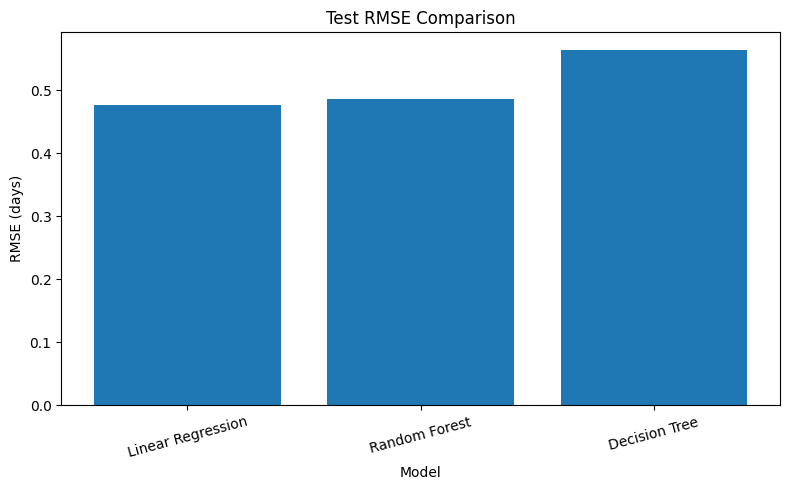

In [6]:
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["Test RMSE (days)"])
plt.title("Test RMSE Comparison")
plt.xlabel("Model")
plt.ylabel("RMSE (days)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


Hyperparameter tuning

In [7]:
rf_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=42))
])
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}
grid = GridSearchCV(
    rf_pipe, param_grid,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
grid.fit(X_train, y_train)
print("Best parameters:", grid.best_params_)
print("Best 5-fold CV RMSE:", round(-grid.best_score_, 3), "days")


Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 4, 'model__n_estimators': 200}
Best 5-fold CV RMSE: 0.557 days


In [8]:
tuned_predictions = grid.best_estimator_.predict(X_test)
mae = mean_absolute_error(y_test, tuned_predictions)
rmse = mean_squared_error(y_test, tuned_predictions) ** 0.5
r2 = r2_score(y_test, tuned_predictions)

print("Tuned Random Forest Test Results")
print("MAE:", round(mae, 3), "days")
print("RMSE:", round(rmse, 3), "days")
print("R-squared:", round(r2, 3))


Tuned Random Forest Test Results
MAE: 0.388 days
RMSE: 0.48 days
R-squared: 0.851


Prediction review

In [9]:
prediction_results = X_test.copy()
prediction_results["actual_delivery_time_days"] = y_test
prediction_results["predicted_delivery_time_days"] = tuned_predictions
prediction_results["absolute_error_days"] = abs(
    prediction_results["actual_delivery_time_days"] -
    prediction_results["predicted_delivery_time_days"]
)
display(prediction_results.head(10))
prediction_results.to_csv("week4_test_predictions.csv", index=False)


,distance_km,shipment_volume_units,transport_cost_inr,promised_delivery_days,transport_mode,region,actual_delivery_time_days,predicted_delivery_time_days,absolute_error_days
24,576.2,108,3388.60,3.5,Rail,South,3.4,3.576043,0.176043
6,356.2,493,4335.71,5.4,Road,West,5.3,5.302609,0.002609
93,373.8,473,4392.91,3.4,Rail,West,3.4,3.899654,0.499654
109,485.7,379,3118.98,2.9,Rail,South,2.8,3.094179,0.294179
104,388.1,392,2763.27,1.0,Rail,West,1.5,1.309142,0.190858
172,254.5,48,3938.27,1.0,Air,East,0.7,1.284870,0.584870
233,384.4,390,6160.51,1.0,Air,East,1.0,1.332768,0.332768
86,470.0,40,3578.53,4.1,Road,South,3.9,3.985631,0.085631
9,459.0,46,4187.99,3.1,Road,South,3.9,3.868570,0.031430
143,208.0,60,2329.24,1.1,Road,South,1.8,1.809827,0.009827


In [11]:
print("The week-4 Project are Succesfulley Complited");

The week-4 Project are Succesfulley Complited
